# <center> __Fisher Matrix__

# Importing python modules

In [1]:
import numpy as np
import scipy as sc
from scipy.special import erf
import pandas as pd
from icecream import ic

#Get angular power spectrum for galaxy number counts and lensing
import camb
# from camb.sources import SplinedSourceWindow
# from camb import model

# Visualizing matrices
import matplotlib.pyplot as plt
# from matplotlib.colors import TwoSlopeNorm
# from matplotlib.colors import LogNorm
# from matplotlib.colors import SymLogNorm 
# from matplotlib.colors import LinearSegmentedColormap
# from matplotlib import ticker

# #Corner plot
# from matplotlib.gridspec import GridSpec
# import scipy.stats as stats

# Plots style
plt.rc('font',  size      = 12 )   # controls default text sizes
plt.rc('axes',  titlesize = 12 )   # fontsize of the axes title
plt.rc('xtick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('ytick', labelsize = 12 )   # fontsize of the tick labels
plt.rc('legend',fontsize  = 12 )   # legend fontsize
plt.rc('axes',  labelsize = 14 )   # fontsize of the x and y labels
plt.rc('figure',titlesize = 16 )   # fontsize of the figure title

# **Functions** 

### Euclid - [Monatnari 2015](http://dx.doi.org/10.1088/1475-7516/2015/10/070)

Euclid preparation: XIX. Impact of magnification on photometric
galaxy clustering:

central redshifts [0.14, 0.26, 0.39, 0.53, 0.69, 0.84, 1.0, 1.14, 1.3, 1.44, 1.62, 1.78, 1.91] 

but we will only consider the firs 10 z-bins: 
[0.14, 0.26, 0.39, 0.53, 0.69, 0.84, 1.0, 1.14, 1.3, 1.44] 

In [2]:
# Montanari Euclid parameters
def pz_Euclid(z, z0):
    pz = z**2 * np.exp( -(z/z0)**(3/2) )
    return pz

def gal_bias_Euclid(z, b0=1):
    b_z = b0 * np.sqrt(1+z)
    del b0
    return b_z

def mag_bias_Euclid(z, s_0 = 0.1194, s_1 = 0.2122, s_2 = -0.0671, s_3 = 0.1031):
    s_z = s_0 + s_1*z + s_2*z**2 + s_3*z**3
    del s_0, s_1, s_2, s_3
    return np.round(s_z, 3)

z0_Euclid = 0.9/1.42      # z_mean = 0.9
N_gal_Euclid = 3.5*10**8  # galaxies / redshift / steradian

# from  Euclid preparation: XIX. Impact of magnification on photometric galaxy clustering
arr_z_central_Euclid = [0.14, 0.26, 0.39, 0.53, 0.69, 0.84, 1.0, 1.14, 1.3, 1.44]  

### DES initial parameters - [Fonseca 2016](https://academic.oup.com/mnras/article/466/3/2780/2679644)

In [3]:
#Set bins for DES

def pz_DES(z, z0=0.57):
    return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2

def gal_bias_DES(z):
    return 1+0.84*z

def mag_bias_DES(z, s0=0.132, s1=0.259, s2=0.281, s3=0.691, s4=0.409, s5=0.152):
    s_z = s0 + s1*z - s2*z**2 + s3*z**3 - s4*z**4 + s5*z**5
    del s0, s1, s2, s3, s4, s5
    return s_z

z0_DES = 0.57
N_gal_DES      = 22.36 # galaxies / redshift / arcmin^2
N_gal_DES_deg2 = N_gal_DES * 1 / (1/60)**2   # galaxies / redshift * 1/deg^2
N_gal_DES_str  = N_gal_DES_deg2 * 1 / (np.pi/180)**2 #deg^2 to strd; galaxies / redshift * 1/strd
ic(N_gal_DES, N_gal_DES_deg2, N_gal_DES_str)


ic| N_gal_DES: 22.36
    N_gal_DES_deg2: 80496.0
    N_gal_DES_str: 264252779.95054534


(22.36, 80496.0, 264252779.95054534)

In [4]:
# #bins and bins details
# nbins=10
# zc=np.zeros(nbins)
# sz=np.zeros(nbins)
# cap=1/nbins

# z_int=np.arange(0.35,3.001,0.001)
# per_gal=np.zeros(len(z_int))
# tot_gal_overlap=quad(lambda x: func(x,amp_dndz_Sr,alpha, z0, beta),0.35,2.05)[0]
# for i in range(len(z_int)):
#     per_gal[i]=quad(lambda x: func(x,amp_dndz_Sr,alpha, z0, beta),0.35,z_int[i])[0]/tot_gal_overlap


# ## binning starts at z=0.35
# z_extremes=[0.35]
# pers=np.arange(cap,1.01,cap)
# for i in range(len(pers)):
#     z_extremes.append(z_int[np.argwhere(per_gal<pers[i])[-1][0]])
# #z_extremes.append(2.5)
# #print(z_extremes)

# for i in range(nbins):
#     zc[i]=round((z_extremes[i]+z_extremes[i+1])/2,3)
#     sz[i]=round((z_extremes[i+1]-z_extremes[i])/2,3)
    
# photo_z_uncertainty=np.around(0.05*(1+zc),3)
# print(zc)
# print(sz)
# print(photo_z_uncertainty)

# def W(z,zi,si,photo_z_uncertainty):
#     return (erf((zi+si-z)/(np.sqrt(2)*photo_z_uncertainty))-
#             erf((zi-si-z)/(np.sqrt(2)*photo_z_uncertainty)))/2


### LSST initial parameters - [LSST Collaboration](https://arxiv.org/abs/1809.01669)

__Y10__

We assume 10 tomographic bins spaced by 0.1 in photo-z between 0.2 ≤ z ≤ 1.2.

b(z) = 0.95/G(z)

G(z = 0) = 1

σz = 0.03(1 + z)

N_gal_LSST_Y10 = 48 # arcmin**-2

$$ dN/dz ∝ z² \exp [−(z/z0 )^α] $$
 
z0 = .28, alpha = 0.90

For Y10, they were [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943].

__Y1__

We assume 5 tomographic bins spaced by 0.2 in photo-z between 0.2 ≤ z ≤ 1.2.

N_gal_LSST_Y10 = 18 # arcmin**-2

(z0 , α) = (0.26, 0.94) 

For Y1, the per-bin bias values that were actually used were [1.562362, 1.732963, 1.913252, 2.100644, 2.293210]. 

In [5]:
sigma_val_LSST = 0.03

# Y1 - 5 redshift bins
def pz_LSST_Y1(z, z0):
    alpha = 0.94
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y1 = 0.26
N_gal_LSST_Y1 = 18  # galaxies / redshift / arcmin^-2
N_gal_LSST_Y1_str = N_gal_LSST_Y1 * 1 / (1/60)**2 * 1 / (np.pi/180)**2  # galaxies / redshift / str
ic(N_gal_LSST_Y1_str)

arr_z_central_LSST_Y1 = np.arange(0.2, 1.2, 0.2)

arr_gal_bias_LSST_Y1 = np.array( [1.562362, 1.732963, 1.913252, 2.100644, 2.293210] )

# Y10 - 10 redshit bins
def pz_LSST_Y10(z, z0):
    alpha = 0.90
    pz = z**2 * np.exp(-(z/z0)**(alpha) )
    return pz

z0_LSST_Y10 = 0.28
N_gal_LSST_Y10 = 48  # galaxies / redshift / arcmin^2
N_gal_LSST_Y10_str = N_gal_LSST_Y10 * 1 / (1/60)**2 * 1 / (np.pi/180)**2  # galaxies / redshift / str

arr_z_central_LSST_Y10 = np.arange(0.2, 1.2, 0.1)

arr_gal_bias_LSST_Y10 = np.array( [1.376695, 1.451179, 1.528404, 1.607983, 1.689579, 1.772899, 1.857700, 1.943754, 2.030887, 2.118943] )




#### Mag bias = ???

ic| N_gal_LSST_Y1_str: 212725851.48076102


In [6]:
def bias(z,sample):
    if sample=='red':
        return 1+z
    if sample=='full':
        return 1+0.84*z
    else:
        return 0

### Importing my own functions

In [7]:
import sys
sys.path.insert(0, "/home/tiagosinde/Documents/Programar/My_Python_functions/")  # add Python_functions path to search list

# Creating and combining Redshift bins 
from Galaxy_Distribution import Window_func

# Calculate C_ell
from Calculate_C_ell_CAMB import C_ells_CAMB

# Fisher Covariance Matrix
from Fisher_Matrix_C_ell_w_theta import *


# **Fisher Matrix**  $w(\theta )$ vs $C_\ell$

\begin{split}
    F_{\alpha\beta} &\simeq \mu_{,\alpha}^T C^{-1} \mu_{,\beta} \\
    F_{\alpha\beta} &\simeq \frac{\partial\mu^T}{\partial \lambda_\alpha} (\Gamma_{\theta\theta', ijpq})^{-1} \frac{\partial\mu}{\partial \lambda_\beta}						
\end{split}

## Initial parameters

In [45]:
def Window_func_Gal_HI(arr_zs, arr_z_central, z0, Ngal, sigma_val=0.05, arr_bin_width=None, 
                       func_pz=None, func_Tz=None, W_func="W_Gauss", N_bins_Gal=1000, HI_Gal=False,
                       Show_WS=False, fig_size=(7,5), Fig_y_unit=r"gal \, / \, deg^2", Fig_Ws_name="Default_Ws_name"):
    # Gives an array of Gaussian distributions. 
    # One Window for each central redshift given.
    
    def W_Gauss(arr_zs, z_c, arr_sigma_z):
        return np.exp(- (arr_zs-z_c)**2 / (2*arr_sigma_z**2))  # we don't need to normalize this expresion, since CAMB already does it internally

    def W_erf(z,zi,bin_width,photo_z_uncertainty):
        return (erf((zi+bin_width-z)/(np.sqrt(2)*photo_z_uncertainty)) - 
                erf((zi-bin_width-z)/(np.sqrt(2)*photo_z_uncertainty)) ) / 2
    
    
    # Gal. Dist. function
    if func_pz == None:
        def pz_DES(z, z0=0.57):
            return (z/z0)**1.04*np.exp(-(z/z0)**1.34)  # arcmin**-2
        func_pz = pz_DES
    
    # HI Temperature distribution
    if func_Tz == None:
        def Temp_HI(z):
            return 0.055919 + 0.23242 * z - 0.024136 * z**2
        func_Tz = Temp_HI

    arr_sigma_z = sigma_val*(1+arr_zs)
    N_bins_Total = len(arr_z_central)
    if HI_Gal==False:
        N_bins_Gal = N_bins_Total
    

    dic_Window = {}
    dNdz = func_pz(arr_zs, z0)*Ngal   # we don't need to normalize this expresion, since CAMB already does it internally
    dic_Window[ "Total" ] = dNdz

        
    for index_zc, z_c in enumerate(arr_z_central):
        if W_func=="W_Gauss":
            dic_Window[ z_c ] = dNdz * W_Gauss(arr_zs, z_c, arr_sigma_z)
        elif W_func=="W_erf":
            bin_width = arr_bin_width[index_zc]
            dic_Window[ z_c ] = dNdz * W_erf(arr_zs, z_c, bin_width, arr_sigma_z)

        # if index_zc < N_bins_Gal:
        #     if W_func=="W_Gauss":
        #         dic_Window[ z_c ] = dNdz * W_Gauss(arr_zs, z_c, arr_sigma_z)
        #     elif W_func=="W_erf":
        #         bin_width = arr_bin_width[index_zc]
        #         dic_Window[ z_c ] = dNdz * W_erf(arr_zs, z_c, bin_width, arr_sigma_z)
        # else:
        #     if W_func=="W_Gauss":
        #         dic_Window[ z_c ] = np.mean(Temp_HI(arr_zs)) * W_Gauss(arr_zs, z_c, arr_sigma_z)
        #     elif W_func=="W_erf":
        #         bin_width = arr_bin_width[index_zc]
        #         dic_Window[ z_c ] = np.mean(Temp_HI(arr_zs)) * W_erf(arr_zs, z_c, bin_width, arr_sigma_z)
        #         ic(Temp_HI(z_c))
        

    # Visualizing the selcted bins
    if Show_WS == True:

        fig, axis = plt.subplots(nrows=1, ncols=2, figsize=(17, 5))   
        axis[0].plot(arr_zs, dic_Window[ "Total" ] , "--", lw=2,  c= "k", label="Total gal. dist.")
        
        for index_zc in range(N_bins_Gal):
            z_c = arr_z_central[index_zc]
            axis[0].plot(arr_zs, dic_Window[ z_c ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
            
            axis[0].fill_between( arr_zs, dic_Window[ z_c ], y2=np.zeros(len( dic_Window[ z_c ] )), alpha=0.25 )

        axis[0].set_xlabel('$z$',fontsize=18)
        axis[0].set_ylabel(r"$\frac{dN}{dzd\Omega} \;\;$"+rf"$[{Fig_y_unit}]$",fontsize=18)
        axis[0].set_title("Galaxy Survey")
        axis[0].legend()

        for index_zc in range(N_bins_Gal, N_bins_Total):
            z_c = arr_z_central[index_zc]
            axis[1].plot(arr_zs, dic_Window[ z_c ], lw=2.5, label=rF"$W_{{ {index_zc+1} }}: z_c = {z_c :.3f}$")
            axis[1].fill_between( arr_zs, dic_Window[ z_c ], y2=np.zeros(len( dic_Window[ z_c ] )), alpha=0.25 )

        axis[1].set_xlabel('$z$',fontsize=18)
        axis[1].set_ylabel("Temperature [units=??]",fontsize=18)
        axis[1].set_title("HI Survey")
        axis[1].legend()


        if Fig_Ws_name != "Default_Ws_name":
            plt.savefig("Figures/" + Fig_Ws_name + ".png")
        plt.show()
        
        
    del index_zc, z_c, N_bins_Total, dNdz, arr_sigma_z
    
    return dic_Window


In [138]:
#For HI

def bias_HI(z):
    return 0.66655 + 0.17765 * z + 0.050223 * z**2

def Temp_HI(z):
    return 0.055919 + 0.23242 * z - 0.024136 * z**2

sHI=0.4
# bHI=np.around(b_hi(zc),3)
# THI=np.zeros(nbins)
# for i in range(len(zc)):
#     THI[i]=np.around(quad(lambda x: t_hi(x)* W(x,zc[i],sz[i],photo_z_uncertainty[i])/norm_w[i],0,3)[0],3) #in mK


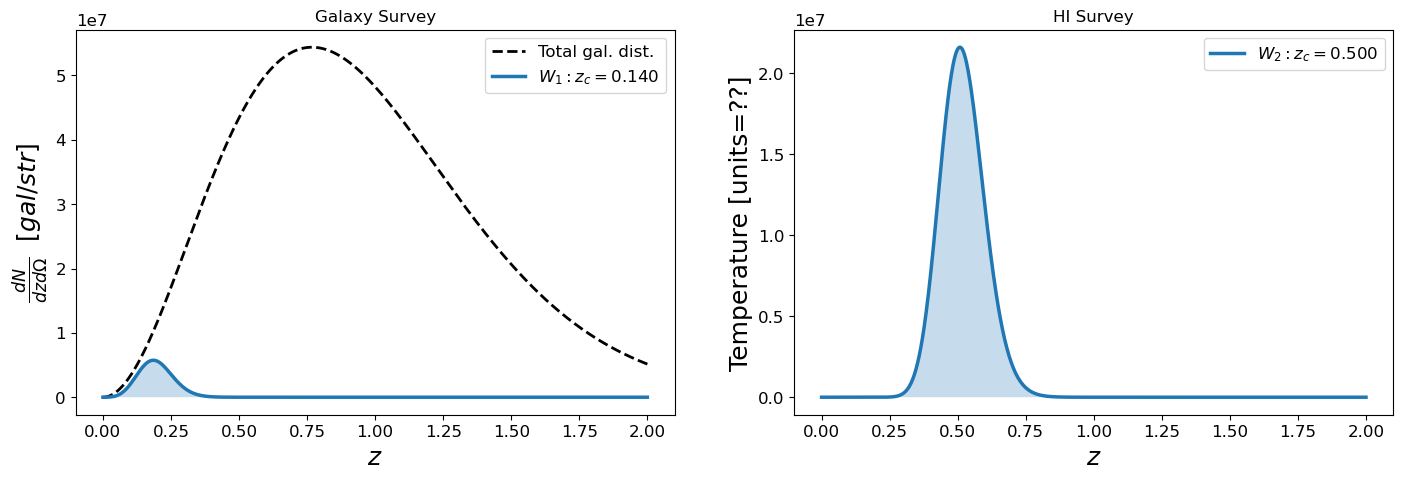

In [124]:
# Galaxy Surveys
Survey_Gal = "Euclid"
# Survey_Gal = "DES"
# Survey_Gal = "LSST_Y1"
# Survey_Gal = "LSST_Y10"
N_bins_Gal = 1

# HI Surveys
nu_ref = 1420.0 # MHz, frequency of the HI line
Survey_HI = "Meerkat"
arr_z_central_Meerkat = np.array( [0.5, 0.6, 0.7, 0.8, 0.9, 1.0] )
arr_nu_central_Meerkat = nu_ref / (arr_z_central_Meerkat+1)

# Survey_HI = "SKA"

N_bins_HI  = 1


N_bins_Total = N_bins_Gal+N_bins_HI


####################################### initial parameters ###############################################


# Creating central redshifts and redshift combinations
arr_z_central = np.zeros(N_bins_Total)
arr_bin_width = np.zeros(N_bins_Total)

arr_bin_width_nu = np.zeros(N_bins_HI)


for i in range(N_bins_Total):

    if i < N_bins_Gal:
        # ic("Gal")
        if Survey_Gal == "Euclid":
            arr_z_central[i] = arr_z_central_Euclid[i]
            arr_bin_width[i] = np.abs(arr_z_central_Euclid[i] - arr_z_central_Euclid[i+1])/2
    
    else:
        # ic("HI")
        index_HI = i-N_bins_Gal
        if Survey_HI == "Meerkat":
            arr_z_central[i] = arr_z_central_Meerkat[index_HI]
            arr_bin_width[i] = np.abs(arr_z_central_Meerkat[index_HI] - arr_z_central_Meerkat[index_HI+1])/2
        
            arr_bin_width_nu[index_HI] = np.abs(arr_nu_central_Meerkat[index_HI] - arr_nu_central_Meerkat[index_HI+1])/2 


Data_arr_zs_auto= np.zeros((N_bins_Total,2))
Data_arr_zs_full= np.zeros( (int(N_bins_Total*(N_bins_Total+1)/2), 2) )   # The number of elements in a triangular matrix of size n×n is given by the formula n(n+1)​/2
count = 0
for i in range(N_bins_Total):

    z_c_i = arr_z_central[i]
    Data_arr_zs_auto[i] = np.array( [z_c_i, z_c_i] )

    for j in range( N_bins_Total -i ):
        z_c_j = arr_z_central[i+j]  # We do i+j since we don't want to repeat combinations 
        Data_arr_zs_full[count] = np.array( [z_c_i, z_c_j] )
        count+=1

del i, j, z_c_i, z_c_j, count


# Calculate Redshift bins
arr_zs = np.linspace(0, 2, 1000)
sigma_val = 0.05
arr_sigma_z = sigma_val*(1+arr_zs)

if Survey_Gal == "Euclid" and Survey_HI == "Meerkat":
    dic_Window  = Window_func_Gal_HI(arr_zs, arr_z_central, z0_Euclid, N_gal_Euclid, 
                                     sigma_val=sigma_val, arr_bin_width=arr_bin_width, func_pz=pz_Euclid, W_func="W_erf",
                                     N_bins_Gal=N_bins_Gal, HI_Gal=True, 
                                     Show_WS=True, Fig_y_unit="gal/str")



Galaxy Surveys

In [11]:
# Survey = "Euclid"
# # Survey = "DES"
# # Survey = "LSST_Y1"
# # Survey = "LSST_Y10"

# N_bins = 5
# # N_bins = 10

# ####################################### initial parameters ###############################################


# # Creating central redshifts and redshift combinations
# arr_bin_width = np.zeros(N_bins)

# if Survey == "Euclid":
#     arr_z_central = arr_z_central_Euclid[0:N_bins]
#     for i in range(N_bins):
#         arr_bin_width[i] = np.abs(arr_z_central_Euclid[i] - arr_z_central_Euclid[i+1])/2

# elif Survey == "DES":
#     if N_bins ==5:
#         arr_z_central = arr_z_central_LSST_Y1[0:N_bins]
#         for i in range(N_bins):
#             arr_bin_width[i] = np.abs(arr_z_central_LSST_Y1[i] - arr_z_central_LSST_Y1[i+1])/2
#     elif N_bins==10:
#         arr_z_central = arr_z_central_LSST_Y10[0:N_bins]
#         for i in range(N_bins):
#             arr_bin_width[i] = np.abs(arr_z_central_LSST_Y10[i] - arr_z_central_LSST_Y10[i+1])/2
#     # arr_z_central = arr_z_central_DES[0:N_bins]

# elif Survey == "LSST_Y1":
#     arr_z_central = arr_z_central_LSST_Y1[0:N_bins]
#     for i in range(N_bins):
#         arr_bin_width[i] = np.abs(arr_z_central_LSST_Y1[i] - arr_z_central_LSST_Y1[i+1])/2
# elif Survey == "LSST_Y10":
#     arr_z_central = arr_z_central_LSST_Y10[0:N_bins]
#     for i in range(N_bins):
#         arr_bin_width[i] = np.abs(arr_z_central_LSST_Y10[i] - arr_z_central_LSST_Y10[i+1])/2


# Data_arr_zs_auto= np.zeros((N_bins,2))
# Data_arr_zs_full= np.zeros( (int(N_bins*(N_bins+1)/2), 2) )   # The number of elements in a triangular matrix of size n×n is given by the formula n(n+1)​/2
# count = 0
# for i in range(N_bins):
#     z_c_i = arr_z_central[i]
#     Data_arr_zs_auto[i] = np.array( [z_c_i, z_c_i] )
#     for j in range(N_bins-i):
#         z_c_j = arr_z_central[i+j]  # We do i+j since we don't want to repeat combinations 
#         Data_arr_zs_full[count] = np.array( [z_c_i, z_c_j] )
#         count+=1
# del i, j, z_c_i, z_c_j, count


# # Calculate Redshift bins
# arr_zs = np.linspace(0, 2, 1000)
# sigma_val = 0.05
# arr_sigma_z = sigma_val*(1+arr_zs)

# if Survey == "Euclid":
#     dic_Window  = Window_func(arr_zs, arr_z_central, z0_Euclid, N_gal_Euclid, 
#                               sigma_val=sigma_val, arr_bin_width=arr_bin_width,
#                               func_pz=pz_Euclid, W_func="W_erf", Show_WS=True, Fig_y_unit="gal/str")
# elif Survey == "DES":
#     dic_Window  = Window_func(arr_zs, arr_z_central, z0_DES, N_gal_DES_str, 
#                               sigma_val=sigma_val, arr_bin_width=arr_bin_width,
#                               func_pz=pz_DES, W_func="W_erf", Show_WS=True, Fig_y_unit="gal/str")
# elif Survey == "LSST_Y1":
#     dic_Window  = Window_func(arr_zs, arr_z_central, z0_LSST_Y1, N_gal_LSST_Y1_str, 
#                               sigma_val=sigma_val_LSST, arr_bin_width=arr_bin_width,
#                               func_pz=pz_LSST_Y1, W_func="W_erf", Show_WS=True, Fig_y_unit="gal/str")
# elif Survey == "LSST_Y10":
#     dic_Window  = Window_func(arr_zs, arr_z_central, z0_LSST_Y10, N_gal_LSST_Y10_str, 
#                               sigma_val=sigma_val_LSST, arr_bin_width=arr_bin_width, 
#                               func_pz=pz_LSST_Y10, W_func="W_erf", Show_WS=True, Fig_y_unit="gal/str")


## Comological parameters + $\beta$ or + $s(z)$

I calculate the Cov Matrix and the derivatives of $C_\ell$ once, for the entirety of the $\ell$ range.

Afterwards, if we want to remove some of that $\ell s$ we can still use the original matrix, since the functions select the relevant data.

**Note:** even if we want to cut some $\theta s$ out of our analysis, $w(\theta)$ still needs the entire CovM of $C_\ell$ as input.

In [48]:
# Portion of the sky
f_sky = 1.00
# f_sky = 0.33
f_sky_str = str(round(f_sky, 2))[0] + str(round(f_sky, 2))[2:]


# Range of theta and ell values

theta_max = 90
# theta_max = 18

#coupled
l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] )
#decoupled
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +10
# l_min = np.max( [int(180/theta_max) + (180 % theta_max > 0), 2] ) +20


l_max = 1000

theta_min = 180/l_max
theta_min_str = str(round(theta_min, 2))[0] + str(round(theta_min, 2))[2:]

ic(theta_min, theta_max) 
ic(l_min, l_max)
ic(f_sky, f_sky_str)


########################################################## Parameters for w(theta) #############################
theta_val = theta_min
theta_step = 0.2
N_thetas = int((theta_max - theta_min)/theta_step) +1
ic(N_thetas)
thetas = np.empty( N_thetas )
count=0

while theta_val < theta_max:
    thetas[count] = theta_val
    theta_val += theta_step
    count+=1

full_l_min = 2
full_l_max = 1000
ells = np.arange(full_l_min, full_l_max+1, 1)

Pol_Legend = np.zeros( (N_thetas, len(ells))  )
for index_t, teta in enumerate(thetas):
    for index_l, l in enumerate(ells):
        Pol_Legend[index_t,index_l] = sc.special.lpmv(0, l, np.cos( np.radians(teta) ))

ic| theta_min: 0.18, theta_max: 90
ic| l_min: np.int64(2), l_max: 1000
ic| f_sky: 1.0, f_sky_str: '10'
ic| N_thetas: 450


#### Test for either $\beta$ or $s(z)$

In [74]:
set_name = "beta"
# set_name = "sz"
# set_name = "both"


# dic_Cosm_param={"parameter_name" : ["par_info", fiducial_value, h_value]
dic_Cosm_param= {
                  "H0"        : ['hubble_const' , 67.27           , 0.7       ],    # H = 100 h    km s-1 Mpc-1
                  'w'         : ['w'            , -1              , 0.05      ],
                  'Ob'        : ['omega_baryon' , 0.0492          , 10**-4    ],
                  'Ocdm'      : ['omega_cdm'    , 0.2647          , 10**-3    ], 
                  "As"        : ["curv_amp"     , 2.2065          , 10**-2    ],    # comoving curvature power at k=pivot_scalar
                  "ns"        : ["spec_index"   , 0.9645          , 10**-2    ]     # scalar spectral index
                  }


# Magnification bias values, s(z)
dic_mag_bias = {}
if Survey_Gal=="Euclid" and Survey_HI=="Meerkat":
    for i, z_c in enumerate(arr_z_central):
        if i < N_bins_Gal:
            dic_mag_bias[z_c] = mag_bias_Euclid(z_c)
        else:
            dic_mag_bias[z_c] = 2/5
            
# z_count = 0
# for key in (dic_Cosm_param.keys()):
#     if dic_Cosm_param[key][0] == "mag_bias": 
#         dic_mag_bias[arr_z_central[z_count]] = dic_Cosm_param[key][1]
#         z_count+=1
# if dic_mag_bias == {} and Survey_Gal=="Euclid":
#     for z_c in arr_z_central:
#         dic_mag_bias[z_c] = mag_bias_Euclid(z_c)
# elif dic_mag_bias == {} and Survey_Gal=="DES":
#     for z_c in arr_z_central:
#         dic_mag_bias[z_c] = mag_bias_DES(z_c)
ic(dic_mag_bias)



if set_name=="beta":
    dic_Cosm_param["beta"] = ['beta', 1, 10**-2]

elif set_name=="both" and Survey_Gal == "Euclid" and Survey_HI=="Meerkat":
    dic_Cosm_param["beta"] = ['beta', 1, 10**-2]

    for index_zc, z_c in enumerate(arr_z_central):
        dic_Cosm_param[f"s_{index_zc+1}"] = ["mag_bias", dic_mag_bias[z_c], 10**-3]

# if set_name=="beta":
#     dic_Cosm_param["beta"] = ['beta', 1, 10**-2]
# elif set_name=="sz" and Survey_Gal == "DES":
#     for z_i in arr_z_central:
#         dic_Cosm_param[f"s_{z_i+1}"] = ["mag_bias", mag_bias_DES(z_i), 10**-3]
# elif set_name=="sz" and Survey_Gal == "Euclid":
#     for z_i in arr_z_central:
#         dic_Cosm_param[f"s_{z_i+1}"] = ["mag_bias", mag_bias_Euclid(z_i), 10**-3]


ic(dic_Cosm_param)




# folder to save the data in
folder_name = "Fisher_Data/"
# String name to save file
save_filename = f"{Survey_Gal}_{N_bins_Gal}zbins_{N_bins_HI}HIbins_{set_name}"
print(f"{folder_name}_..._{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}")

Fisher_Data/_..._Euclid_1zbins_1HIbins_beta_f10_lmin2_thetaMax90


ic| dic_mag_bias: {np.float64(0.14): np.float64(0.148), np.float64(0.5): 0.4}
ic| dic_Cosm_param: {'As': ['curv_amp', 2.2065, 0.01],
                     'H0': ['hubble_const', 67.27, 0.7],
                     'Ob': ['omega_baryon', 0.0492, 0.0001],
                     'Ocdm': ['omega_cdm', 0.2647, 0.001],
                     'beta': ['beta', 1, 0.01],
                     'ns': ['spec_index', 0.9645, 0.01],
                     'w': ['w', -1, 0.05]}


#### 0. Cosmology and Magnification bias values

In [143]:
############################# Cosmological parameters ####################################

dic_cosmology = {
    'Omega_M': dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1], 
    'Omega_b': dic_Cosm_param["Ob"][1],
    "Omega_cdm" : dic_Cosm_param["Ocdm"][1],
    'Omega_L': 1-(dic_Cosm_param["Ob"][1] + dic_Cosm_param["Ocdm"][1]),
    "H_0":dic_Cosm_param["H0"][1],  
    'h': dic_Cosm_param["H0"][1]/100,
    'w': dic_Cosm_param["w"][1],
    "A_s": dic_Cosm_param["As"][1] *10**-9,
    'n_s': dic_Cosm_param["ns"][1],
    'sigma_8': 0.8
    }


pars = camb.CAMBparams()
pars.set_cosmology(H0=dic_cosmology["H_0"], 
                ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
pars.set_dark_energy( w=dic_cosmology["w"] )
pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])


class: <InitialPowerLaw>
 tensor_parameterization = tensor_param_rpivot
 ns = 0.9645
 nrun = 0.0
 nrunrun = 0.0
 nt = -0.0
 ntrun = -0.0
 r = 0.0
 pivot_scalar = 0.05
 pivot_tensor = 0.05
 As = 2.2065e-09
 At = 1.0
 

#### Testing HI

C_ell

In [76]:
import camb
from camb.sources import SplinedSourceWindow
from camb import model


# Determine Angular Power Spectrum with CAMB
def C_ells_CAMB_HI(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, 
                pars_CAMB="default", source_type="counts", N_count_index="D_RSD_L", goal="default", 
                bias_func_Gal="default", N_bins_Gal=1000,
                bias_func_HI="default", 
                bias_values_Gal = 1.2, s_value=0.01, s_variation=0, Limb_usage=True, Limb_l_min=50):
    
    if pars_CAMB == "default":
        dic_cosmology = {
            'Omega_b': 0.0492,
            "Omega_cdm" : 0.2647,
            'Omega_M': 0.0492 + 0.2647, 
            'Omega_L': 1-(0.0492 + 0.2647),
            "H_0": 67.27,  
            'h': 67.27/100,
            'w': -1,
            "A_s": 2.2065 * 10**-9,
            'n_s': 0.9645,
            'sigma_8': 0.8
            }
        
        pars_CAMB = camb.CAMBparams()
        pars_CAMB.set_cosmology(H0=dic_cosmology["H_0"], 
                        ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                        omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
        pars_CAMB.set_dark_energy( w=dic_cosmology["w"] )
        pars_CAMB.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])
        
        del dic_cosmology

    # Limb_l_min=50 is the Minimum l value used in Limber approx. -- See Section 2. from Fang et. al. 
    pars_CAMB.min_l, pars_CAMB.max_l = l_min, l_max 
    pars_CAMB.Want_CMB, pars_CAMB.Want_CMB_lensing, pars_CAMB.DoLensing = False, False, False
    pars_CAMB.NonLinear = model.NonLinear_none
    pars_CAMB.SourceTerms.counts_velocity        = False
    pars_CAMB.SourceTerms.counts_radial          = False
    pars_CAMB.SourceTerms.counts_timedelay       = False
    pars_CAMB.SourceTerms.counts_ISW             = False
    pars_CAMB.SourceTerms.counts_potential       = False
    pars_CAMB.SourceTerms.counts_evolve          = False
    pars_CAMB.SourceTerms.line_phot_dipole       = False
    pars_CAMB.SourceTerms.line_phot_quadrupole   = False
    pars_CAMB.SourceTerms.line_basic             = False
    pars_CAMB.SourceTerms.line_distortions       = False
    pars_CAMB.SourceTerms.line_extra             = False
    pars_CAMB.SourceTerms.line_reionization      = False
    pars_CAMB.SourceTerms.use_21cm_mK            = False
    pars_CAMB.SourceTerms.limber_windows = Limb_usage
    pars_CAMB.SourceTerms.limber_phi_lmin = Limb_l_min

    
    SSW_list = []
    for index_zc, z_c in enumerate(arr_z_central):
        
        # bias fnction
        if bias_func_Gal != "default":
            bias_values_Gal = bias_func_Gal(z_c) 
        if bias_func_HI != "default":
            bias_values_HI = bias_func_HI(z_c) 

        # Galaxy Window function
        if goal == "derive" and index_zc < N_bins_Gal:
            SSW = SplinedSourceWindow(source_type=source_type, bias=bias_values_Gal, dlog10Ndm=s_value+s_variation, 
                                      z=arr_zs, W=dic_Window[z_c])
        elif goal == "default" and index_zc < N_bins_Gal:    
            SSW = SplinedSourceWindow(source_type=source_type, bias=bias_values_Gal, dlog10Ndm=dic_mag_bias[z_c],   
                                      z=arr_zs, W=dic_Window[z_c])
        
        # HI Window function
        elif goal == "derive" and index_zc >= N_bins_Gal:
            SSW = SplinedSourceWindow(source_type=source_type, bias=bias_values_HI, dlog10Ndm=s_value+s_variation, 
                                      z=arr_zs, W=dic_Window[z_c])
        elif goal == "default" and index_zc >= N_bins_Gal:    
            SSW = SplinedSourceWindow(source_type=source_type, bias=bias_values_HI, dlog10Ndm=dic_mag_bias[z_c],   
                                z=arr_zs, W=dic_Window[z_c])
        SSW_list.append(SSW)

    pars_CAMB.SourceWindows = SSW_list
    
    if N_count_index == "D":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  False, False
    elif N_count_index == "D_RSD":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  False
    elif N_count_index == "D_RSD_L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = True,  True,  True
    elif N_count_index == "L":
        pars_CAMB.SourceTerms.counts_density, pars_CAMB.SourceTerms.counts_redshift, pars_CAMB.SourceTerms.counts_lensing = False, False, True
    
    dic_C_ls = camb.get_results(pars_CAMB).get_source_cls_dict(raw_cl=True)
    
    
    del z_c, index_zc, bias_values_Gal, SSW, SSW_list
    
    return dic_C_ls

Beam

In [77]:
### Constants and conversion
c_light=2.998e5#in Km/s
HI=1420 #MHz

### fized parameters
Ndishes=60
Ddish=13.5


def Beam_ell(z_c, l, 
             Ddish=13.5, c_light=2.998e5, # in Km/sHI=1420
             HI=1420 # MHz
             ):

    def lamb(nu):
        ## nu in Hz
        return c_light*1e3/nu
    
    def nu_obs(z):
        return HI/(1+z)
    
    def theta_fwhm(lamb,D):
        ## lamb in m
        ## D in m
        return 1.22*lamb/D

    def theta(zc,D):
        lamb_obs=lamb(nu_obs(zc)*1e6)
        return theta_fwhm(lamb_obs,D)
    
    def beam_no_ell(theta_fwhm):
        ## theta_fwhm in rad
        return np.exp(-theta_fwhm**2/16/np.log(2))


    theta_fwhm_mk=theta(z_c,Ddish)
    
    beam_mk=beam_no_ell(theta_fwhm_mk)

    return (beam_mk)**(l*(l+1))

Cov Matrix

Shot Noise HI IM devia ser a eq 18 deste artigo: https://arxiv.org/pdf/1803.07077

In [187]:
def kron_delta(i,j):
    if i == j :
        return 1
    else:
        return 0 


def z_bin_Matrix(Data_arr):
    D = Data_arr
    z_bin_Matrix = np.zeros( (len(D)**2, 1, 4), dtype=np.float64 )
    
    index_M = 0
    for ij in range( len(D) ):
        for pq in range( len(D) ):
            z_i, z_j = D[ij][0], D[ij][1]
            z_p, z_q = D[pq][0], D[pq][1]
            z_bin_Matrix[index_M] = np.array( [z_i, z_j, z_p, z_q] )

            index_M +=1
            
    del D, index_M, pq, z_i, z_j, z_p, z_q
                
    return z_bin_Matrix 

# Covariance matrix to be used in Fisher matrix
def Fisher_CovM_HI_Gal( Data_arr_zs, arr_zs, arr_z_c, dic_Window, l_min, l_max, dic_mag_bias, C_ell_func,
                        S_area=None, N_dishes=None, time_total=None, f_sky=1, arr_bin_width_nu=None, dic_T_sys=None,
                        bias_func_Gal="default", N_bins_Gal=1000, bias_func_HI="default",
                        pars_CAMB="default", verbose=False): 
        
    Matrix_z_bins = z_bin_Matrix(Data_arr_zs)
    N_Matrices = Matrix_z_bins.shape[0]
    ells = np.arange(l_min, l_max+1, 1)
    N_ells = len( ells )


    dic_C_ell_CAMB = C_ell_func(arr_zs, arr_z_c, dic_Window, l_min, l_max, dic_mag_bias, 
                                 pars_CAMB=pars_CAMB, 
                                 bias_func_Gal=bias_func_Gal, N_bins_Gal=N_bins_Gal,
                                 bias_func_HI=bias_func_HI )
    
    dic_C_ell_CovM = {} 
    dic_P_N = {}
    for i, z_c_i in enumerate(arr_z_c):
        for j, z_c_j in enumerate(arr_z_c):

            # Constructing Corrected dictionary of C_ell values     
            if i < N_bins_Gal  and  j < N_bins_Gal: # Gal_i x Gal_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = np.abs(dic_C_ell_CAMB[F"W{i +1}xW{j +1}"] [l_min:l_max+1])  

            elif i >= N_bins_Gal  and  j < N_bins_Gal: # HI_i x Gal_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( np.abs(dic_C_ell_CAMB[F"W{i +1}xW{j +1}"] [l_min:l_max+1]) 
                                                      * Beam_ell(z_c_i, ells, Ddish=13.5) * Temp_HI(z_c_i))

            elif i < N_bins_Gal  and  j >= N_bins_Gal: # Gal_i x HI_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( np.abs(dic_C_ell_CAMB[F"W{i +1}xW{j +1}"] [l_min:l_max+1]) 
                                                      * Beam_ell(z_c_j, ells, Ddish=13.5) * Temp_HI(z_c_j))

            elif i >= N_bins_Gal  and  j >= N_bins_Gal: # HI_i x HI_j
                dic_C_ell_CovM[f"{z_c_i},{z_c_j}"] = ( np.abs(dic_C_ell_CAMB[F"W{i +1}xW{j +1}"] [l_min:l_max+1]) 
                                                      * Beam_ell(z_c_i, ells, Ddish=13.5) * Beam_ell(z_c_j, ells, Ddish=13.5) 
                                                      * Temp_HI(z_c_i)* Temp_HI(z_c_j))
                ic(z_c_i, z_c_j)
                # ic(Beam_ell(z_c_i, ells, Ddish=13.5)* Beam_ell(z_c_j, ells, Ddish=13.5))

            # Constructing dictionaty of Shot Noise values
            if i < N_bins_Gal  and  i == j:
                dic_P_N[z_c_i] = 1/np.sum(dic_Window[z_c_i])
            elif i >= N_bins_Gal  and  i == j:
                
                # Find out which is the best bin of T_sys to use
                Closest_z_Tsys = 10**3
                for Key_i in dic_T_sys.keys():
                    if np.abs(Key_i-z_c_i) < np.abs(Closest_z_Tsys-z_c_i):
                        Closest_z_Tsys = Key_i

                dic_P_N[z_c_i] =  S_area * f_sky * dic_T_sys[Closest_z_Tsys]**2 / (2*N_dishes * time_total * arr_bin_width_nu[i-N_bins_Gal])
                # dic_P_N[z_c_i] =  0
    ic(dic_P_N)


    # Calculate Covariance Matrix
    Multiple_Matrices = np.zeros( (N_Matrices, N_ells, N_ells) )
    for index_M in range( N_Matrices ):
        if (verbose == True) and (index_M % int(N_Matrices/5))==1 and N_Matrices > 20 :
            print(f"Computing small covariance matrix {index_M} of {N_Matrices}")

        calculate = True
        arr_z_c_Matrix = Matrix_z_bins[index_M][0]

        # Check if any previously calculated matrix has the same z-bin combo as this one
        z_i, z_j, z_p, z_q =arr_z_c_Matrix[0],arr_z_c_Matrix[1],arr_z_c_Matrix[2],arr_z_c_Matrix[3]
        for index_old_M in range(index_M-1):
            old_arr_z_c = Matrix_z_bins[index_old_M][0]
            old_z_i, old_z_j, old_z_p, old_z_q = old_arr_z_c[0], old_arr_z_c[1], old_arr_z_c[2], old_arr_z_c[3]
            
            # if so, this matrix is equal to that previous matrix        
            if  z_i==old_z_p and z_j==old_z_q and z_p==old_z_i and z_q == old_z_j :
                Multiple_Matrices[index_M] = Multiple_Matrices[index_old_M]
                calculate = False

            
        if calculate == True:
            Cl_iq = dic_C_ell_CovM[f"{z_i},{z_q}"]  
            Cl_pj = dic_C_ell_CovM[f"{z_p},{z_j}"]
            Cl_ip = dic_C_ell_CovM[f"{z_i},{z_p}"]
            Cl_qj = dic_C_ell_CovM[f"{z_q},{z_j}"]

            P_N_iq = kron_delta(z_i, z_q) * dic_P_N[z_i]                
            P_N_pj = kron_delta(z_p, z_j) * dic_P_N[z_j]
            P_N_ip = kron_delta(z_i, z_p) * dic_P_N[z_i]
            P_N_qj = kron_delta(z_q, z_j) * dic_P_N[z_j]

            # Calculate the Covariance Matrix of a specific redshift combination
            Gamma_ll = np.zeros( (N_ells, N_ells) )
            for index_ell_a in range(N_ells):
                for index_ell_b in range(index_ell_a, N_ells): 
                    value = (  (Cl_iq[index_ell_a]+P_N_iq) *(Cl_pj[index_ell_a]+P_N_pj) 
                             + (Cl_ip[index_ell_a]+P_N_ip) *(Cl_qj[index_ell_a]+P_N_qj) )
                    Gamma_ll[index_ell_a,index_ell_b] = value
                    Gamma_ll[index_ell_b,index_ell_a] = value
            
            Multiple_Matrices[index_M] = Gamma_ll
            
    del Matrix_z_bins, N_Matrices, ells, N_ells, dic_P_N
    del calculate, arr_z_c_Matrix, z_i, z_j, z_p, z_q
    # del index_old_M, old_arr_z_c, old_z_i, old_z_j, old_z_p, old_z_q
    del Cl_iq, Cl_pj, Cl_ip, Cl_qj, P_N_iq, P_N_pj, P_N_ip, P_N_qj
    del dic_C_ell_CAMB, dic_C_ell_CovM, value, Gamma_ll,  index_M, index_ell_a, index_ell_b

    if verbose==True:
        print("Cov Matrix Calculated!")
        
    return Multiple_Matrices

In [188]:
Sa=5000
#Sa=1500
Omega_surv=Sa*(np.pi/180)**2
t10k=1300
tobs=t10k*Sa/10000
N_dishes=60

#system temperature and N antennas
# tsys_band1=np.loadtxt('band1_Tsys.txt')
tsys_uhf=np.loadtxt('Codes_Ze/UHF_Tsys.txt')
# N_ska=133
# N_mk=64

# Freq[MHz]    T_sys[K]    A_effective/T[m^2/K]
# print(tsys_uhf)

N_nu = len(tsys_uhf[:,0])
arr_zs_Tsys = np.zeros(N_nu)
dic_T_sys = {}
for i in range(N_nu):
    z_i = np.around(nu_ref / tsys_uhf[:,0][i] - 1,3)
    arr_zs_Tsys[i] = z_i
    dic_T_sys[z_i] = tsys_uhf[:,1][i]



ic| z_c_i: np.float64(0.5), z_c_j: np.float64(0.5)
ic| dic_P_N: {np.float64(0.14): np.float64(2.2074102587038256e-09),
              np.float64(0.5): np.float64(0.0002897115328591056)}
ic| Cov_Matrix_auto.shape: (4, 999, 999)
ic| N_ells: np.int64(999)
ic| Cov_Matrix.shape: (4, 999, 999)


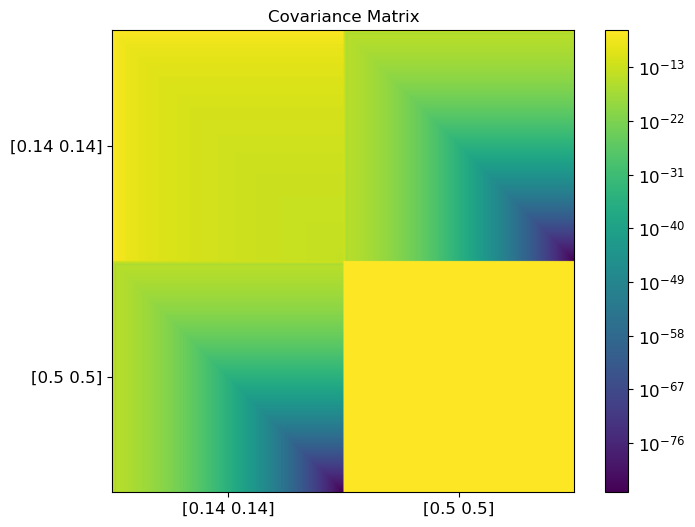

In [189]:


Cov_Matrix_auto = Fisher_CovM_HI_Gal(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, 
                              dic_mag_bias, C_ells_CAMB_HI, 
                              S_area=Omega_surv, N_dishes=N_dishes, time_total=tobs, f_sky=f_sky, arr_bin_width_nu=arr_bin_width_nu, dic_T_sys=dic_T_sys,
                              bias_func_Gal=gal_bias_Euclid, N_bins_Gal=N_bins_Gal, bias_func_HI=bias_HI,
                              pars_CAMB=pars)

ic(Cov_Matrix_auto.shape)
Visualizing_Cov_Matrix(Data_arr_zs_auto, l_min, l_max, Cov_Matrix_auto)


Confirm Cov matrix is calculated correctly

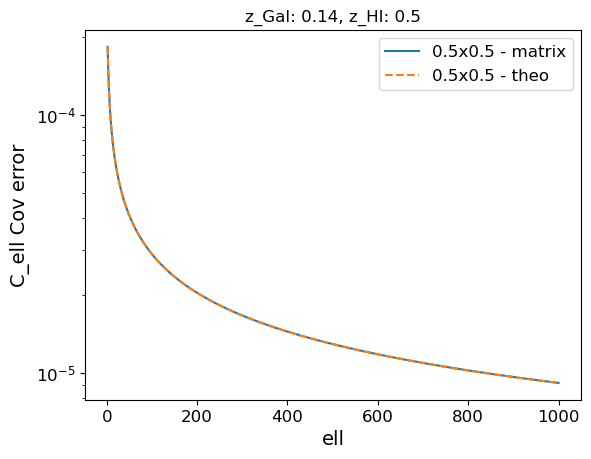

In [195]:

# plt.plot(ells, f_sky/((2*ells+1)) * np.diagonal(Cov_Matrix_auto[0]), label=f"{arr_z_central[0]}x{arr_z_central[0]}")
# plt.plot(ells, f_sky/((2*ells+1)) * np.diagonal(Cov_Matrix_auto[1]), label=f"{arr_z_central[0]}x{arr_z_central[1]}")
# plt.plot(ells, f_sky/((2*ells+1)) * np.diagonal(Cov_Matrix_auto[2]), label=f"{arr_z_central[1]}x{arr_z_central[0]}")

plt.plot(ells, np.sqrt(f_sky/((2*ells+1)) * np.diagonal(Cov_Matrix_auto[3])), label=f"{arr_z_central[1]}x{arr_z_central[1]} - matrix")

dic_C_ell = C_ells_CAMB_HI(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, 
                                pars_CAMB=pars, 
                                bias_func_Gal=gal_bias_Euclid, N_bins_Gal=N_bins_Gal,
                                bias_func_HI=bias_HI)
z_c_i = arr_z_central[1]
z_c_j = arr_z_central[1]
C_ell_i = (np.abs(dic_C_ell[F"W{1 +1}xW{1 +1}"] [l_min:l_max+1]) 
                 * Beam_ell(z_c_i, ells, Ddish=13.5) * Beam_ell(z_c_j, ells, Ddish=13.5) 
                 * Temp_HI(z_c_i)* Temp_HI(z_c_j) )
P_N_i = Omega_surv * f_sky * dic_T_sys[0.495]**2 / (2*N_dishes * tobs * arr_bin_width_nu[0])
Delta_C_ell = (np.sqrt(2/(2*ells+1)*1/(f_sky)) * (C_ell_i + P_N_i))

plt.plot( ells, Delta_C_ell, "--", label=f"{arr_z_central[1]}x{arr_z_central[1]} - theo")
plt.xlabel("ell")
plt.ylabel("C_ell Cov error")
plt.yscale("log")
plt.legend()
plt.title(f"z_Gal: {arr_z_central[0]}, z_HI: {arr_z_central[1]}")
plt.show()



Derivatives

In [135]:
# Five-point stencil: Numerical derivation approxiamtion
def f_pt_sten_Cls(f, x, h_spacing, Cosm_p_info, dic_Cosm_p, arr_zs, arr_z_central, 
                  dic_Window, l_min, l_max, dic_mag_bias, 
                  bias_func_Gal=None, bias_func_HI=None, N_bins_Gal=1000 ):

    dic_cosmology = {
        'Omega_M': dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1], 
        'Omega_b': dic_Cosm_p["Ob"][1],
        "Omega_cdm" : dic_Cosm_p["Ocdm"][1],
        'Omega_L': 1-(dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1]),
        "H_0":dic_Cosm_p["H0"][1],  
        'h': dic_Cosm_p["H0"][1]/100,
        'w': dic_Cosm_p["w"][1],
        "A_s": dic_Cosm_p["As"][1] *10**-9,
        'n_s': dic_Cosm_p["ns"][1],
        'sigma_8': 0.8
        }

    pars = camb.CAMBparams()
    pars.set_cosmology(H0=dic_cosmology["H_0"], 
                       ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                       omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
    pars.set_dark_energy( w=dic_cosmology["w"] )
    pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

    variations = [2*h_spacing, h_spacing, -h_spacing, -2*h_spacing]
    dic_C_ells = {}
    
    if Cosm_p_info == "mag_bias":
        # pars.set_cosmology(H0=dic_cosmology["H_0"], 
        #                    ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
        #                    omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
        # pars.set_dark_energy(w=dic_cosmology["w"])
        # pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])
        for index_var, var in enumerate(variations):
            C_ell = f(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, 
                      pars_CAMB=pars, goal="derive", 
                      bias_func_Gal=bias_func_Gal, N_bins_Gal=N_bins_Gal,  
                      s_value=x, s_variation=var)
            dic_C_ells[index_var+1] = np.abs( C_ell["W1xW2"][l_min:l_max+1] )
            
    else: 
        # Define cosmology while derivating
        def set_cosmology_param(val):
            if Cosm_p_info == "hubble_const":
                New_h = val / 100
                pars.set_cosmology(H0=val, 
                                   ombh2=dic_cosmology["Omega_b"]*New_h**2, 
                                   omch2=dic_cosmology["Omega_cdm"]*New_h**2)
                del New_h
            elif Cosm_p_info == "w":
                pars.set_dark_energy(w=val)
            elif Cosm_p_info == "omega_baryon":
                New_Omega_cdm = dic_cosmology["Omega_M"] - val
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=val*dic_cosmology["h"]**2, 
                                   omch2=New_Omega_cdm*dic_cosmology["h"]**2)
                del New_Omega_cdm
            elif Cosm_p_info == "omega_cdm":
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                                   omch2=val*dic_cosmology["h"]**2)
            elif Cosm_p_info == "spec_index":
                pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=val)
            
        for index_var, var in enumerate(variations):            
            pars.set_cosmology(H0=dic_cosmology["H_0"], 
                               ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                               omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
            pars.set_dark_energy(w=dic_cosmology["w"])
            pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

            set_cosmology_param(x + var)
            C_ell = f(arr_zs, arr_z_central, dic_Window, l_min, l_max, dic_mag_bias, 
                      pars_CAMB=pars, 
                      bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal)
            dic_C_ells[index_var+1] = np.abs( C_ell["W1xW2"][l_min:l_max+1] )
    
    # Calculate derivative using 5-point stencil coefficients
    deriv_approx = (-   dic_C_ells[1] 
                    + 8*dic_C_ells[2] 
                    - 8*dic_C_ells[3] 
                    +   dic_C_ells[4] ) / (12*h_spacing) 

    del variations       
    del index_var, var, C_ell, dic_C_ells

    return deriv_approx


# Derivatives of Fisher matrix
def Fisher_derivative_HI(  Data_arr_zs, arr_zs, dic_Window, l_min, l_max, dic_mag_bias, dic_Cosm_p, C_ell_func,
                        dic_cosmology=None,
                        bias_func_Gal=None, bias_func_HI=None, N_bins_Gal=1000):
    
    dic_cosmology = {
        'Omega_M': dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1], 
        'Omega_b': dic_Cosm_p["Ob"][1],
        "Omega_cdm" : dic_Cosm_p["Ocdm"][1],
        'Omega_L': 1-(dic_Cosm_p["Ob"][1] + dic_Cosm_p["Ocdm"][1]),
        "H_0":dic_Cosm_p["H0"][1],  
        'h': dic_Cosm_p["H0"][1]/100,
        'w': dic_Cosm_p["w"][1],
        "A_s": dic_Cosm_p["As"][1] *10**-9,
        'n_s': dic_Cosm_p["ns"][1],
        'sigma_8': 0.8
        }

    N_Data = len(Data_arr_zs)
    ells = np.arange(l_min, l_max+1, 1)
    N_ells = len(ells)
    arr_z_central = list(dic_Window.keys())
    arr_z_central.remove("Total")

    pars = camb.CAMBparams()
    dic_derivatives = {}

    
    for key in dic_Cosm_p.keys():
        print(key)
    
        Cosm_p_info = dic_Cosm_p[key][0]
        Cosm_p_fid  = dic_Cosm_p[key][1]
        Cosm_p_h_val= dic_Cosm_p[key][2]
    
        arr_dCl_dalpha = np.zeros( N_Data * N_ells)

        for index_bin in range(0, N_Data): 
            arr_z_c_Data = Data_arr_zs[index_bin]
            z_i, z_j = arr_z_c_Data[0],  arr_z_c_Data[1]
            
            if Cosm_p_info == "mag_bias":                
                # z_i, z_j = arr_z_c_Data[0],  arr_z_c_Data[1]
                s_i, s_j = dic_mag_bias[z_i], dic_mag_bias[z_j]

                # if both s parameters differ from the value that we are derivating in order of,  then derivatives are null
                Wrong_bins = (Cosm_p_fid!=s_i and Cosm_p_fid!=s_j)
                if Wrong_bins == True:
                    dCl_dalpha = np.zeros( N_ells )  
                else:
                    dCl_dalpha = f_pt_sten_Cls(C_ell_func, Cosm_p_fid, Cosm_p_h_val, Cosm_p_info, dic_Cosm_p, 
                                               arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                               bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal) 
                del s_i, s_j, Wrong_bins
                
            elif Cosm_p_info == "beta":
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                                   omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
                pars.set_dark_energy(w=dic_cosmology["w"])
                pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])

                C_ell_Tot   = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                        N_count_index="D_RSD_L", 
                                        bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal)
                C_ell_L     = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                        N_count_index="L", 
                                        bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal)
                C_ell_D_RSD = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                        N_count_index="D_RSD", 
                                        bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal)
                
                dCl_dalpha = (  np.abs(C_ell_Tot  ["W1xW2"][l_min:l_max+1]) 
                              + np.abs(C_ell_L    ["W1xW2"][l_min:l_max+1]) 
                              - np.abs(C_ell_D_RSD["W1xW2"][l_min:l_max+1]) )
                del C_ell_Tot, C_ell_L, C_ell_D_RSD

            elif Cosm_p_info == "curv_amp":
                pars.set_cosmology(H0=dic_cosmology["H_0"], 
                                   ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                                   omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
                pars.set_dark_energy(w=dic_cosmology["w"])
                pars.InitPower.set_params(As=dic_Cosm_p["As"][1], ns=dic_cosmology["n_s"])
                C_ell = C_ell_func(arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                   N_count_index="D_RSD_L", 
                                   bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI, N_bins_Gal=N_bins_Gal)
                dCl_dalpha = np.abs(C_ell  ["W1xW2"][l_min:l_max+1]) / Cosm_p_fid
                del C_ell
            
            else:
                dCl_dalpha = f_pt_sten_Cls( C_ell_func, Cosm_p_fid, Cosm_p_h_val, Cosm_p_info,  dic_Cosm_p,
                                            arr_zs, arr_z_c_Data, dic_Window, l_min, l_max, dic_mag_bias, 
                                            bias_func_Gal=bias_func_Gal, bias_func_HI=bias_func_HI , N_bins_Gal=N_bins_Gal) 
            
            # Check if z-bin is of type HI
            z_i_HI, z_j_HI = False, False 
            for index_zc, z_c in enumerate(arr_z_central):
                if z_i == z_c and index_zc >= N_bins_Gal: 
                    z_i_HI = True
                if z_j == z_c and index_zc >= N_bins_Gal: 
                    z_j_HI = True
                # >= <

            if z_i_HI==True and z_j_HI==True:
                arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = (  dCl_dalpha 
                                                                           * Beam_ell(z_i, ells, Ddish=13.5) * Beam_ell(z_j, ells, Ddish=13.5) )
            if z_i_HI==True and z_j_HI==False:
                arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = (  dCl_dalpha * Beam_ell(z_i, ells, Ddish=13.5) )
            if z_i_HI==False and z_j_HI==True:
                arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = (  dCl_dalpha * Beam_ell(z_j, ells, Ddish=13.5) )


            arr_dCl_dalpha[N_ells*index_bin : N_ells*(1+index_bin)] = dCl_dalpha

            
        dic_derivatives[key] = arr_dCl_dalpha


    del N_Data, ells, N_ells, key, index_bin, arr_z_c_Data
    del Cosm_p_info, Cosm_p_fid, Cosm_p_h_val, dCl_dalpha, arr_dCl_dalpha
        
    print("Derivatives Calculated!")
    
    return dic_derivatives



In [136]:
dic_derivatives_auto = Fisher_derivative_HI(Data_arr_zs_auto, arr_zs, dic_Window, full_l_min, full_l_max, 
                                            dic_mag_bias, dic_Cosm_param, C_ells_CAMB_HI,
                                            bias_func_Gal=gal_bias_DES, bias_func_HI=gal_bias_HI, N_bins_Gal=N_bins_Gal )  

H0
w
Ob
Ocdm
As
ns
beta
Derivatives Calculated!


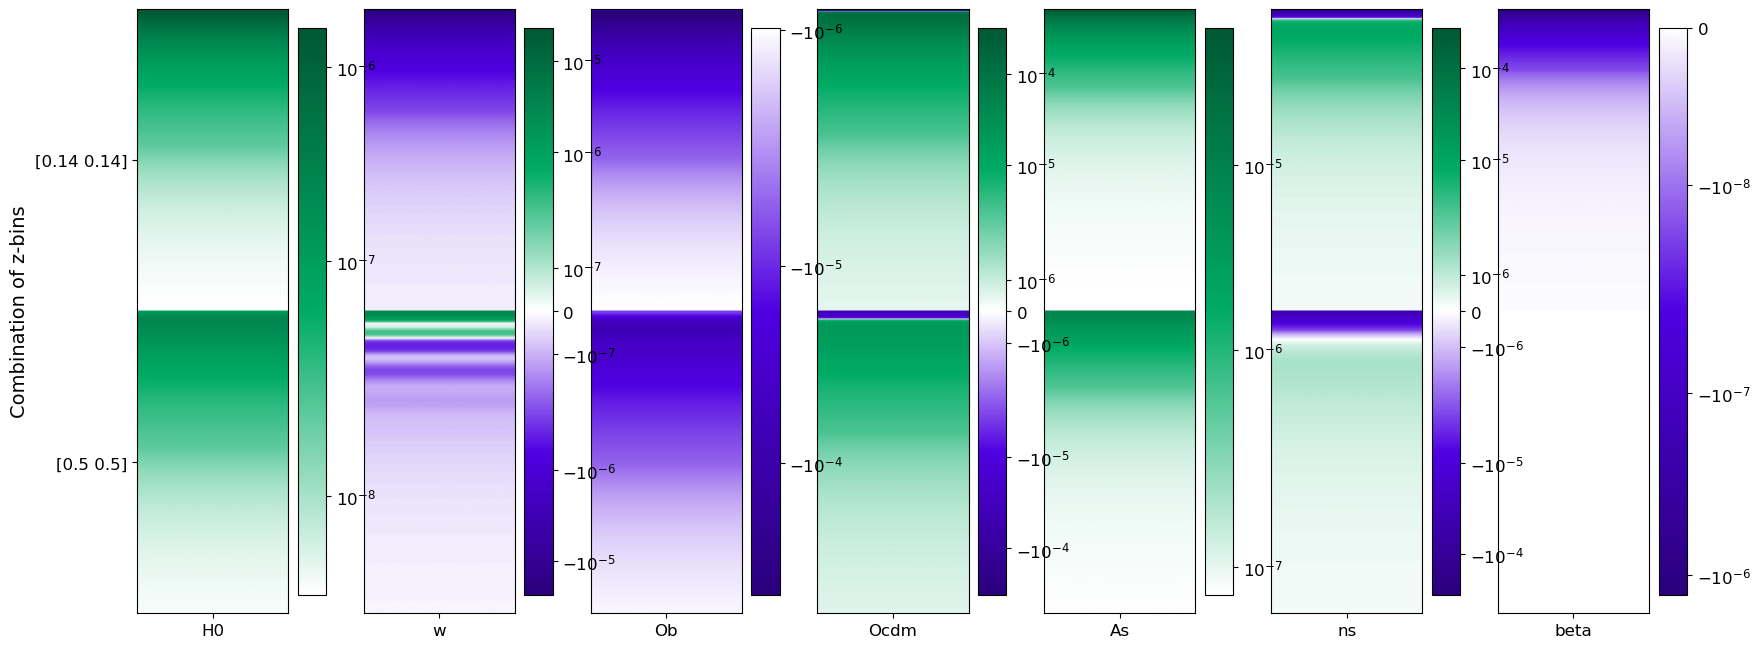

ic| dic_derivatives_auto["beta"][2*l_max:]: array([], dtype=float64)


array([], dtype=float64)

In [137]:
Visualizing_derivatives( Data_arr_zs_auto, l_min, l_max, dic_Cosm_param, dic_derivatives_auto )
ic(dic_derivatives_auto["beta"][2*l_max:])

ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(3996.0)
    N_data*N_ells: 3996


LinAlgError: Singular matrix

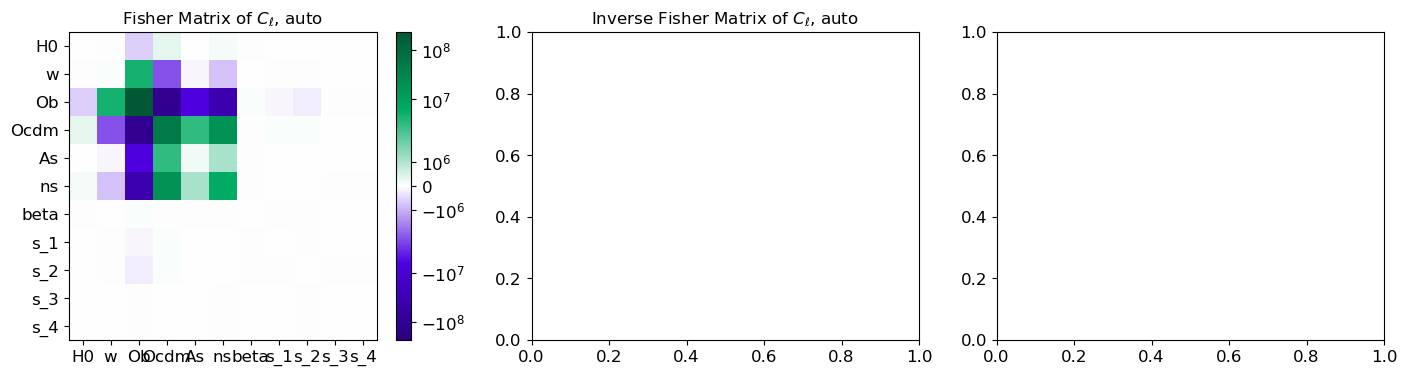

In [28]:
Fish_Cl_auto = Fisher_Matrix_Cl(Data_arr_zs_auto, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                                full_l_min, l_min, full_l_max, l_max, f_sky=f_sky)

Visualising_F_Matrices( Fish_Cl_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $C_\ell$, auto",r"Inverse Fisher Matrix of $C_\ell$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_Cl_auto = pd.DataFrame(data=Fish_Cl_auto.astype(float))
df_Cl_auto.to_csv(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                  sep=' ', header=False, float_format='%.8g', index=False)

ic| Big_Matrix.shape: (1800, 1800)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(1799.9999999998695)
    N_data*N_thetas: 1800


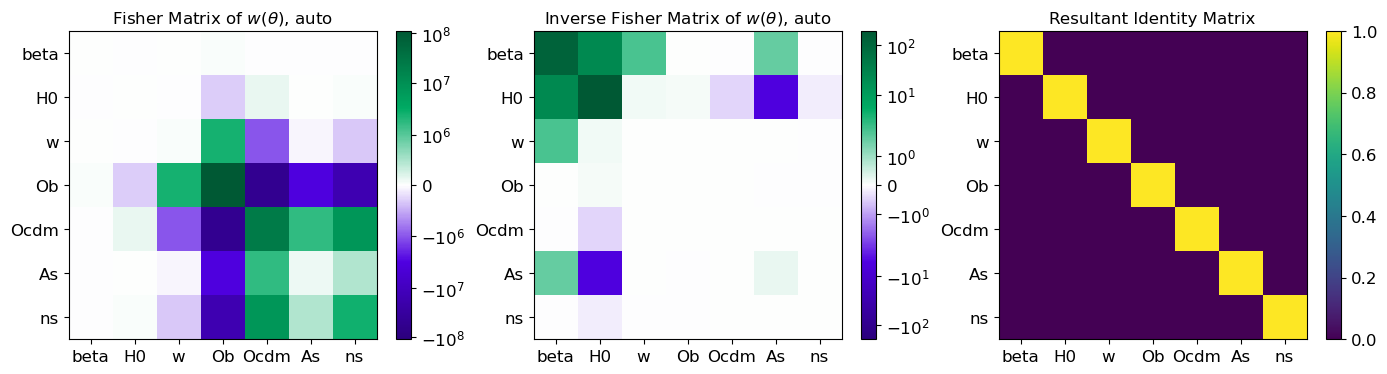

ic| np.sum(Matrix @ Matrix_inv): np.float64(6.999999990993875)


In [119]:
Fish_w_auto = Fisher_Matrix_w(Data_arr_zs_auto, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                              f_sky=f_sky, verbose=False)

Visualising_F_Matrices( Fish_w_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, auto",r"Inverse Fisher Matrix of $w(\theta)$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_w_auto = pd.DataFrame(data=Fish_w_auto.astype(float))
df_w_auto.to_csv(F"{folder_name}FisherM_w_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                 sep=' ', header=False, float_format='%.8g', index=False)

### 1. **Auto** Correlations

#### Calculating Covriance Matrix and derivatives

In [13]:
############################# Calculating Covariant Matrix
if Survey == "Euclid":
    Cov_Matrix_auto = Fisher_CovM(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, 
                                  dic_mag_bias, C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_Euclid)
elif Survey == "DES":
    Cov_Matrix_auto = Fisher_CovM(Data_arr_zs_auto, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, 
                                  dic_mag_bias, C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_DES)

# Visualizing_Cov_Matrix(Data_arr_zs_auto, l_min, l_max, Cov_Matrix_auto)

In [14]:
################################## Calculating derivatives
if Survey == "Euclid":
    dic_derivatives_auto = Fisher_derivative(Data_arr_zs_auto, arr_zs, dic_Window, full_l_min, full_l_max, 
                                             dic_mag_bias, dic_Cosm_param, C_ells_CAMB,
                                             bias_func=gal_bias_Euclid )
if Survey == "DES":
    dic_derivatives_auto = Fisher_derivative(Data_arr_zs_auto, arr_zs, dic_Window, full_l_min, full_l_max, 
                                             dic_mag_bias, dic_Cosm_param, C_ells_CAMB,
                                             bias_func=gal_bias_DES )    

# Visualizing_derivatives( Data_arr_zs_auto, l_min, l_max, dic_Cosm_param, dic_derivatives_auto )

beta
H0
w
Ob
Ocdm
As
ns
Derivatives Calculated!


#### $C_\ell$ auto

ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(4855.0)
    N_data*N_ells: 4855


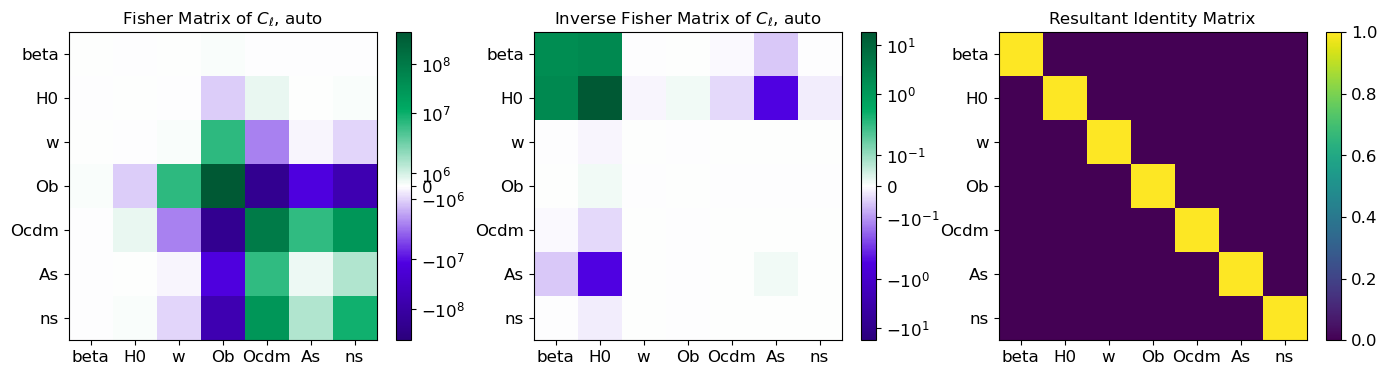

ic| np.sum(Matrix @ Matrix_inv): np.float64(6.999999999856182)


In [30]:
Fish_Cl_auto = Fisher_Matrix_Cl(Data_arr_zs_auto, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                                full_l_min, l_min, full_l_max, l_max, f_sky=f_sky)

Visualising_F_Matrices( Fish_Cl_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $C_\ell$, auto",r"Inverse Fisher Matrix of $C_\ell$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_Cl_auto = pd.DataFrame(data=Fish_Cl_auto.astype(float))
df_Cl_auto.to_csv(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                  sep=' ', header=False, float_format='%.8g', index=False)

#### $w(\theta)$ auto

Computing small covariance matrix 1 of 25
Computing small covariance matrix 6 of 25
Computing small covariance matrix 11 of 25
Computing small covariance matrix 16 of 25
Computing small covariance matrix 21 of 25
Computing derivatives
Fisher Matrix calculated!


ic| Big_Matrix.shape: (450, 450)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(450.00000000011823)
    N_data*N_thetas: 450


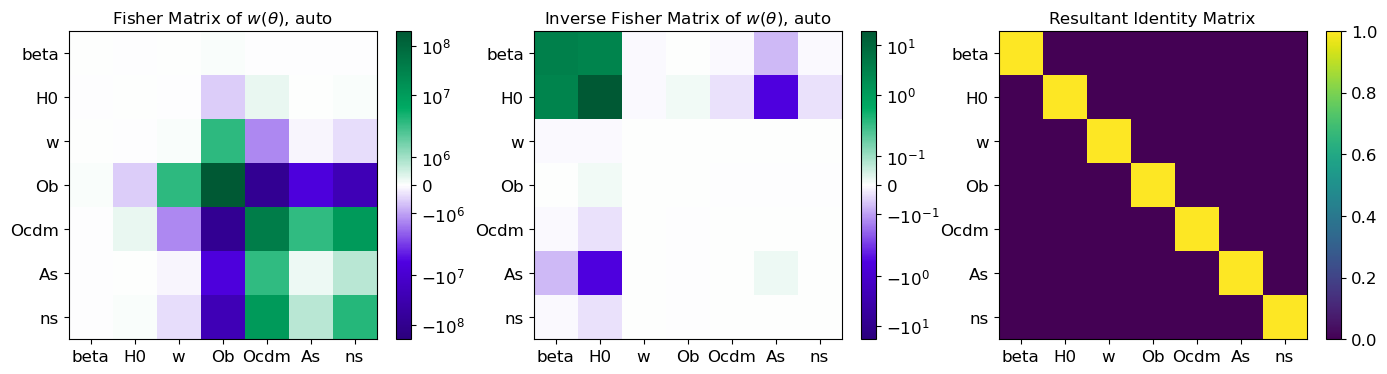

ic| np.sum(Matrix @ Matrix_inv): np.float64(7.000000000444115)


In [31]:
Fish_w_auto = Fisher_Matrix_w(Data_arr_zs_auto, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_auto, dic_derivatives_auto, 
                              f_sky=f_sky, verbose=True)

Visualising_F_Matrices( Fish_w_auto, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, auto",r"Inverse Fisher Matrix of $w(\theta)$, auto",
                                    "Resultant Identity Matrix"])

# Saving data
df_w_auto = pd.DataFrame(data=Fish_w_auto.astype(float))
df_w_auto.to_csv(F"{folder_name}FisherM_w_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                 sep=' ', header=False, float_format='%.8g', index=False)

### 2. **Full** correlations (Auto+Cross)

#### Cov Matrix and derivatives 

In [17]:
pars = camb.CAMBparams()
pars.set_cosmology(H0=dic_cosmology["H_0"], 
                ombh2=dic_cosmology["Omega_b"]*dic_cosmology["h"]**2, 
                omch2=dic_cosmology["Omega_cdm"]*dic_cosmology["h"]**2)
pars.set_dark_energy( w=dic_cosmology["w"] )
pars.InitPower.set_params(As=dic_cosmology["A_s"], ns=dic_cosmology["n_s"])


############################# Calculating Covariant Matrix
if Survey == "Euclid":
    Cov_Matrix_full = Fisher_CovM(Data_arr_zs_full, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                  C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_Euclid, verbose=True)
elif Survey == "DES":
    Cov_Matrix_full = Fisher_CovM(Data_arr_zs_full, arr_zs, arr_z_central, dic_Window, full_l_min, full_l_max, dic_mag_bias, 
                                  C_ells_CAMB, pars_CAMB=pars, bias_func=gal_bias_DES, verbose=True)

# # # Saving data
# df_CovM_full = pd.DataFrame(data=Cov_Matrix_full.astype(float))
# df_CovM_full.to_csv(F"{folder_name}FisherM_CovM_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
#                     sep=' ', header=False, float_format='%.8g', index=False)

# Visualizing_Cov_Matrix(Data_arr_zs_full, l_min, l_max, Cov_Matrix_full, fig_size=(10,8) )

Computing small covariance matrix 1 of 225
Computing small covariance matrix 46 of 225
Computing small covariance matrix 91 of 225
Computing small covariance matrix 136 of 225
Computing small covariance matrix 181 of 225
Cov Matrix Calculated!


In [18]:
################################## Calculating derivatives
if Survey == "Euclid":
    dic_derivatives_full = Fisher_derivative(Data_arr_zs_full, arr_zs, dic_Window, full_l_min, full_l_max, 
                                             dic_mag_bias, dic_Cosm_param, C_ells_CAMB, 
                                             bias_func=gal_bias_Euclid )
if Survey == "DES":
    dic_derivatives_full = Fisher_derivative(Data_arr_zs_full, arr_zs, dic_Window, full_l_min, full_l_max, 
                                             dic_mag_bias, dic_Cosm_param, C_ells_CAMB, 
                                             bias_func=gal_bias_DES )
# Visualizing_derivatives( Data_arr_zs_cross, l_min, l_max, dic_Cosm_param, dic_derivatives_cross, 
#                         aspect_val=1/1500, fig_size=(20,8) )

beta
H0
w
Ob
Ocdm
As
ns
Derivatives Calculated!


#### $C_\ell$ full

ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(14565.0)
    N_data*N_ells: 14565


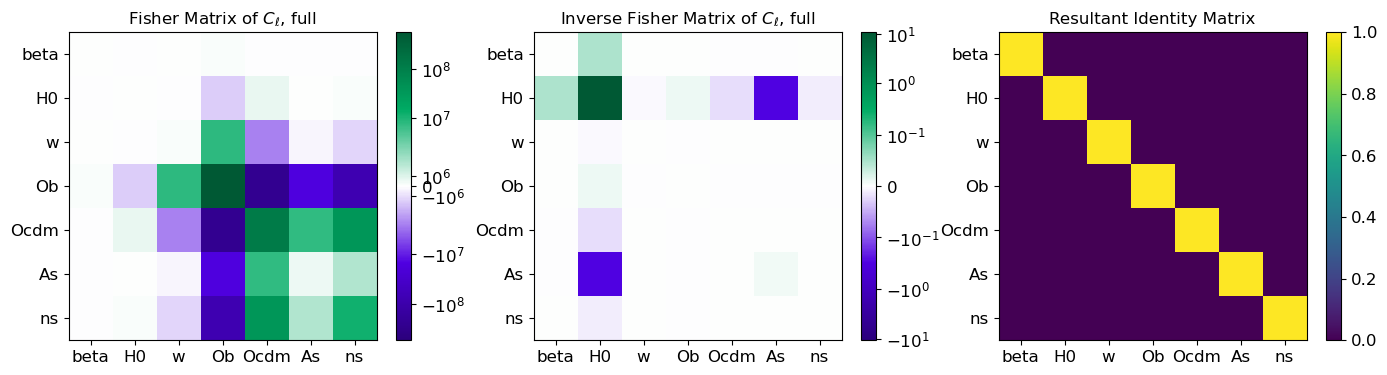

ic| np.sum(Matrix @ Matrix_inv): np.float64(7.000000001532161)


In [32]:
Fish_Cl_full = Fisher_Matrix_Cl(Data_arr_zs_full, dic_Cosm_param, Cov_Matrix_full, dic_derivatives_full, 
                                 full_l_min, l_min, full_l_max, l_max, f_sky=f_sky)

Visualising_F_Matrices(Fish_Cl_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $C_\ell$, full",r"Inverse Fisher Matrix of $C_\ell$, full",
                                    "Resultant Identity Matrix"])
# Saving data
df_Cl_full = pd.DataFrame(data=Fish_Cl_full.astype(float))
df_Cl_full.to_csv(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                  sep=' ', header=False, float_format='%.8g', index=False)

#### $w(\theta)$ full

Computing small covariance matrix 1 of 225
Computing small covariance matrix 46 of 225
Computing small covariance matrix 91 of 225
Computing small covariance matrix 136 of 225
Computing small covariance matrix 181 of 225


ic| Big_Matrix.shape: (1350, 1350)
ic| np.sum( Big_Matrix @ Big_Matrix_inv ): np.float64(1350.000000000239)
    N_data*N_thetas: 1350


Computing derivatives
Fisher Matrix calculated!


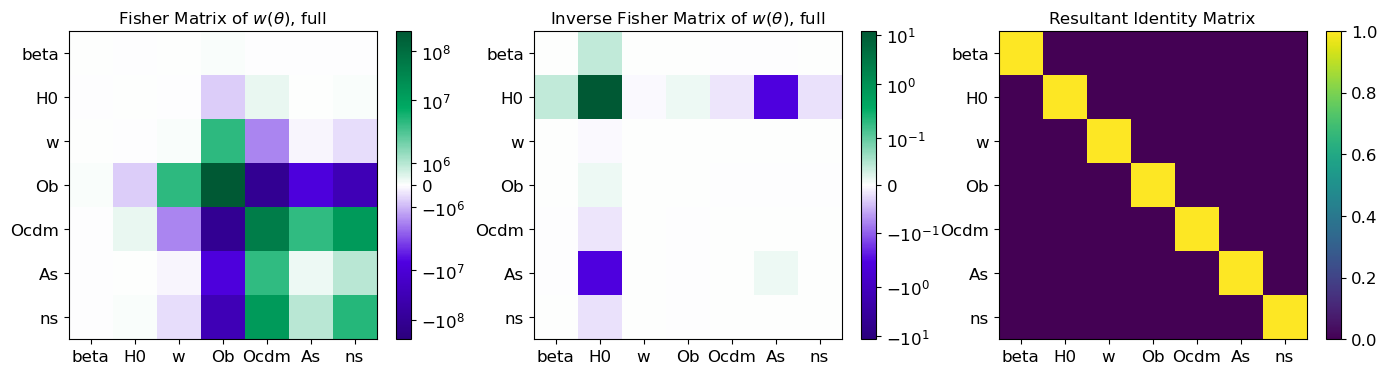

ic| np.sum(Matrix @ Matrix_inv): np.float64(7.000000000177119)


In [33]:
Fish_w_full = Fisher_Matrix_w(Data_arr_zs_full, ells, thetas, Pol_Legend, dic_Cosm_param, Cov_Matrix_full, dic_derivatives_full,
                              f_sky=f_sky, verbose=True)

Visualising_F_Matrices( Fish_w_full, dic_Cosm_param, 
                       list_titles=[r"Fisher Matrix of $w(\theta)$, full",r"Inverse Fisher Matrix of $w(\theta)$, full",
                                    "Resultant Identity Matrix"])

# # Saving data
df_w_full = pd.DataFrame(data=Fish_w_full.astype(float))
df_w_full.to_csv(F"{folder_name}FisherM_w_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", 
                 sep=' ', header=False, float_format='%.8g', index=False)

### 3. Visualise **Corner plots** 

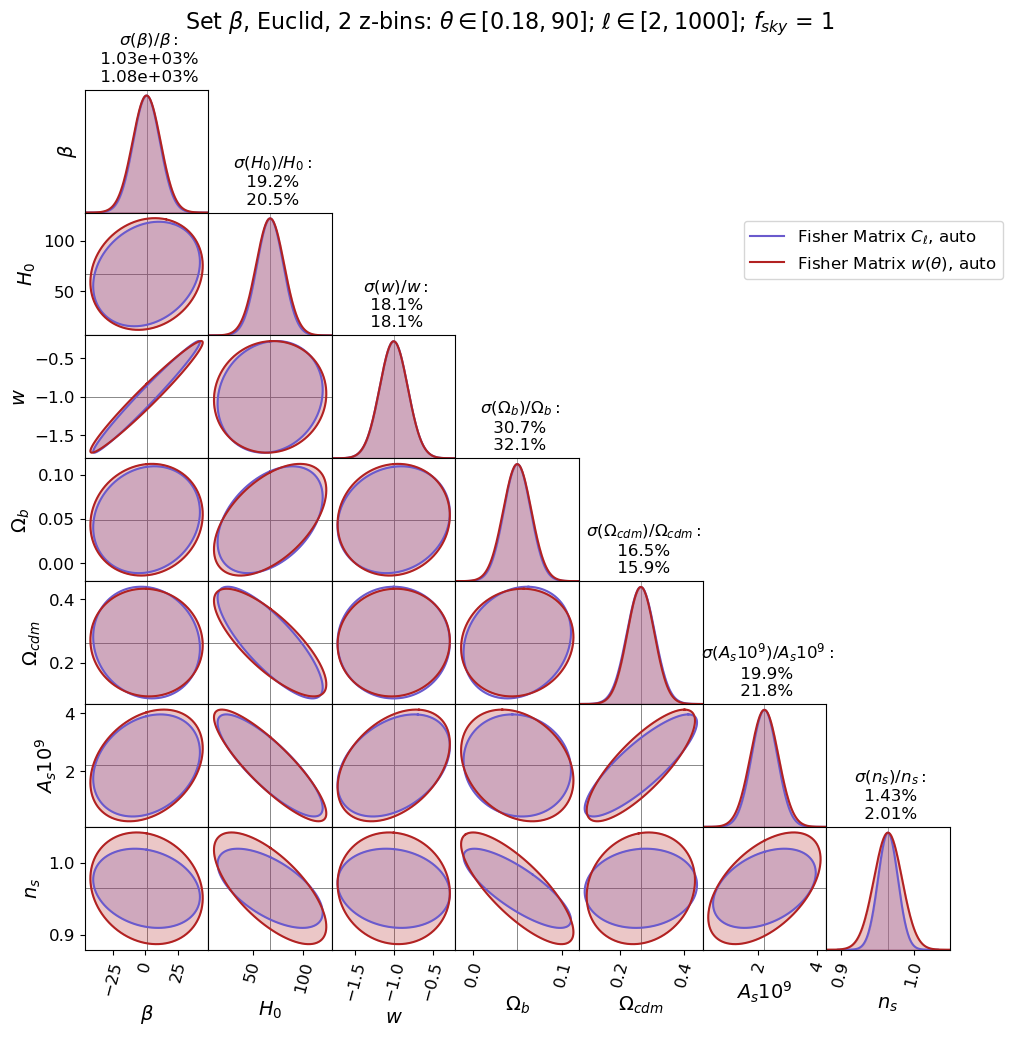

In [120]:
# Importing Fihser Matrices values from  saved data

# f_sky, f_sky_str = 1, 10

# l_min     = 2
# l_min     = 10

# theta_max = 90
# theta_max = 18

FIM_Cl_auto = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
# FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

########################## Corner plots ###################################################################

fid=[]
# counter = 1
for key in dic_Cosm_param.keys():
    fid.append( dic_Cosm_param[key][1] )
    # if counter > 4:
    #     fid.append( dic_Cosm_param[key][1] )
    # counter+=1

par = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]
par_titles = par

# Plot_title = r"$f_{sky}$ = " + rf"{f_sky:.3g}; $z_c = {z_1, z_2, z_3, z_4 }$; $\sigma_z = {sigma_val}$"
# Plot_title = rf"Error Ellipses: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"
Plot_title = rf"Set $\{set_name}$, {Survey_Gal}, {N_bins_Gal} z-bins: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"

name_fig_corner = f"Figures/CornerP_{set_name}_{Survey_Gal}_{N_bins_Gal}z-bins_theta_{theta_min_str}_{theta_max:.3g}-ell_{l_min}_{l_max}-f_sky_{f_sky_str}"

# list_colors = ["#37b67e", "#057041", "#7e71bf", "#4900ac"]
# list_colors = ["dodgerblue", "darkorange", "slateblue", "firebrick"]
list_colors = ["slateblue", "firebrick", "dodgerblue", "darkorange"]


# Only s(z)
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[0:4,0:4]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [0:4,0:4]) ]

# Only Cosm param
# Fishers = [ np.linalg.inv(np.linalg.inv(FIM_Cl_auto) [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_auto)  [4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_Cl_cross)[4:,4:]), 
#             np.linalg.inv(np.linalg.inv(FIM_w_cross) [4:,4:]) ]


# Fishers = [ FIM_Cl_auto, FIM_w_auto, FIM_Cl_full, FIM_w_full ]
# Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto", r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=list_colors, figure_size=(10,8), 
#             Fig_name= name_fig_corner+".png")

Fishers = [ FIM_Cl_auto, FIM_w_auto]
Flabels = [ r"Fisher Matrix $C_\ell$, auto", r"Fisher Matrix $w(\theta)$, auto"  ]
CornerPlot( Fishers, fid, par, par_titles, Plot_title,  Flabels=Flabels, cores=[list_colors[0], list_colors[1]] )

# Fishers = [ FIM_Cl_full, FIM_w_full ]
# Flabels = [ r"Fisher Matrix $C_\ell$, full", r"Fisher Matrix $w(\theta)$, full" ]
# CornerPlot( Fishers, fid, par, par_titles, Plot_title, Flabels=Flabels, cores=[list_colors[2], list_colors[3]], 
#             Fig_name= name_fig_corner+"_full.png")

In [4]:
2**11

2048

### 4. **Compare** performance with histograms

#### Baseline

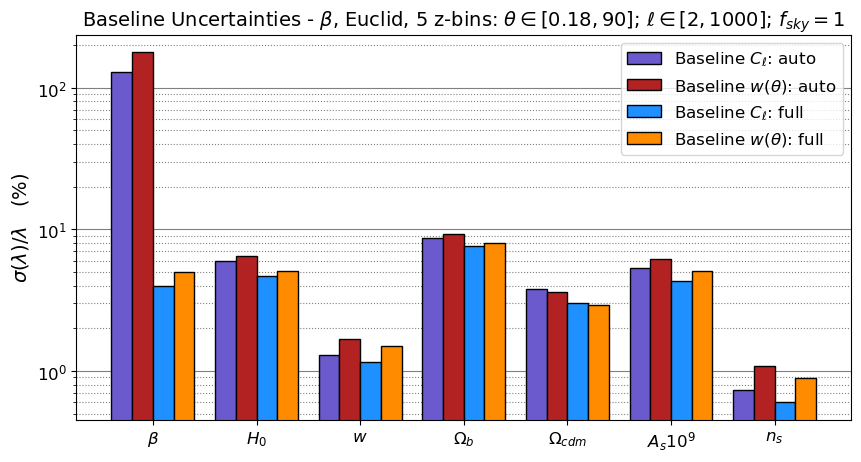

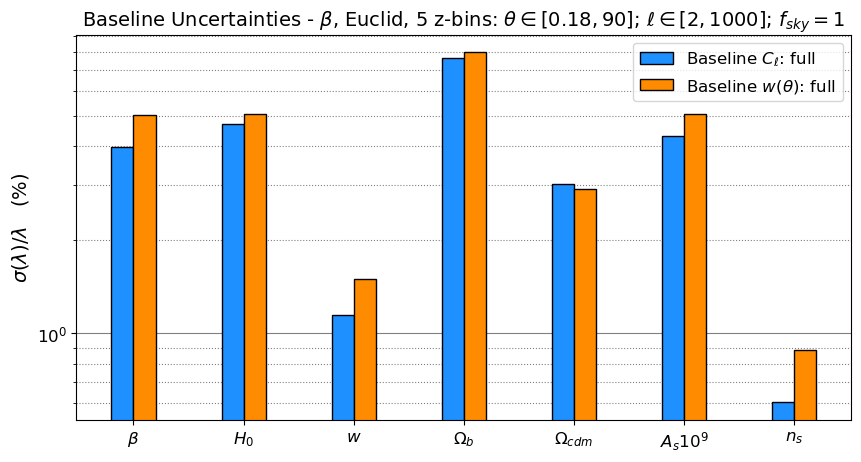

In [24]:
FIM_Cl_auto_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full_Base = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full_Base  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{10}_lmin{2}_thetaMax{90}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto_Base = np.linalg.inv( FIM_Cl_auto_Base)
Inv_FIM_w_auto_Base  = np.linalg.inv( FIM_w_auto_Base )    
Inv_FIM_Cl_full_Base = np.linalg.inv( FIM_Cl_full_Base)  
Inv_FIM_w_full_Base  = np.linalg.inv( FIM_w_full_Base )  

Title_plot = rf"Baseline Uncertainties - $\{set_name}$, {Survey}, {N_bins} z-bins: $\theta \in [{0.18}, {90}]$; $\ell \in [{2}, {1000}]$; " + r"$f_{sky} = 1$"  
name_fig_hist_base = f"Figures/Hist_{set_name}_{Survey}_{N_bins}z-bins_theta_018_90-ell_2_1000-f_sky_10"

list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )

array_Cl_auto_Base = np.zeros( len(list_parameters) )
array_w_auto_Base  = np.zeros( len(list_parameters) )
array_Cl_full_Base = np.zeros( len(list_parameters) )
array_w_full_Base  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto_Base[index_p] = np.sqrt( Inv_FIM_Cl_auto_Base [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto_Base[index_p]  = np.sqrt( Inv_FIM_w_auto_Base [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full_Base[index_p] = np.sqrt( Inv_FIM_Cl_full_Base [index_p,index_p] ) / np.abs(p) * 100
    array_w_full_Base[index_p]  = np.sqrt( Inv_FIM_w_full_Base [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic_Base = { }
Est_Result_dic_Base[r"Baseline $C_\ell$: auto"]    = array_Cl_auto_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: auto"]= array_w_auto_Base
Est_Result_dic_Base[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys= []
for key in Est_Result_dic_Base.keys():
    list_Base_keys.append(key)

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for key in list_Base_keys:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base[key], width, label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+".png")
plt.show()


########################## Plotting only Full correlations ##############################

Est_Result_dic_Base_full = { }
Est_Result_dic_Base_full[r"Baseline $C_\ell$: full"]    = array_Cl_full_Base
Est_Result_dic_Base_full[r"Baseline $w(\theta)$: full"] = array_w_full_Base

list_Base_keys_full= []
for key in Est_Result_dic_Base_full.keys():
    list_Base_keys_full.append(key)

fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for key in list_Base_keys_full:
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_Base_full[key], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\sigma(\lambda) / \lambda \quad (\%)$')
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist_base+"_full.png")
plt.show()

#### Parameters to compare Baseline with

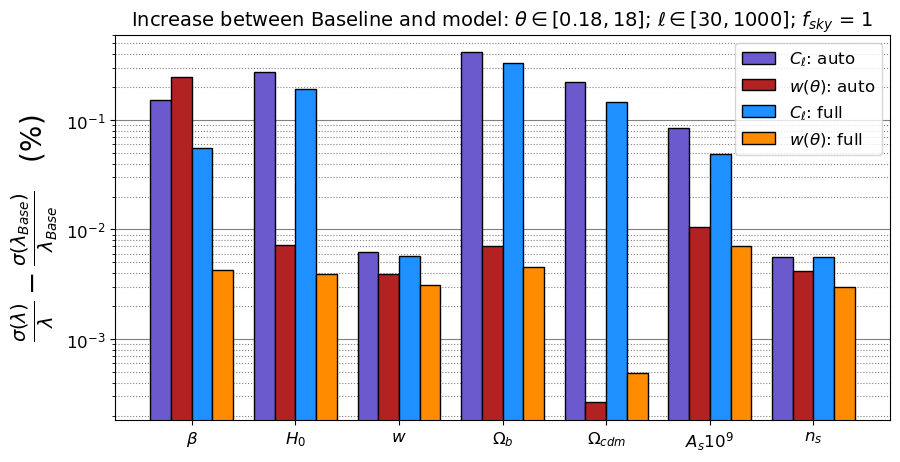

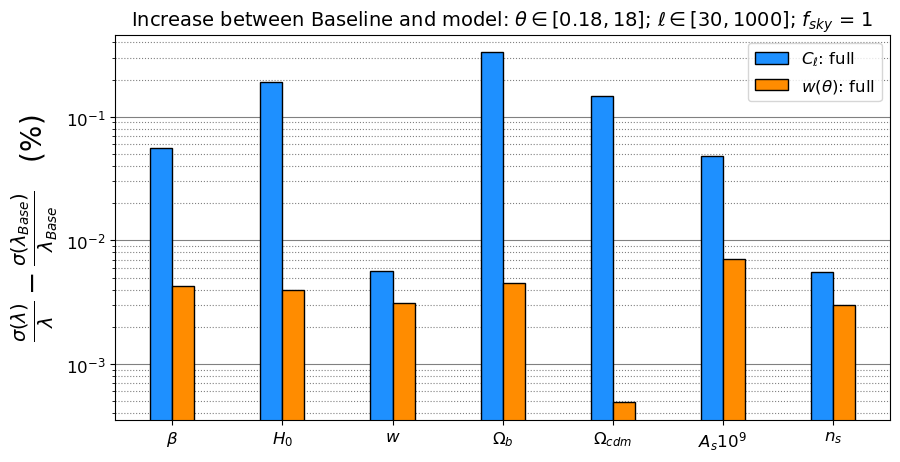

In [35]:
# f_sky, f_sky_str = 1.0, "10"
# f_sky, f_sky_str = 0.33, "033"

# theta_max = 18

# l_min     = 10
# l_min     = 30


FIM_Cl_auto = np.loadtxt(open(F"{folder_name}FisherM_Cl_auto_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_auto  = np.loadtxt(open(F"{folder_name}FisherM_w_auto_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_Cl_full = np.loadtxt(open(F"{folder_name}FisherM_Cl_full_{save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)
FIM_w_full  = np.loadtxt(open(F"{folder_name}FisherM_w_full_{ save_filename}_f{f_sky_str}_lmin{l_min}_thetaMax{theta_max}.csv", "rb"), delimiter=" ", skiprows=0)

Inv_FIM_Cl_auto = np.linalg.inv( FIM_Cl_auto )
Inv_FIM_w_auto  = np.linalg.inv( FIM_w_auto  )    
Inv_FIM_Cl_full = np.linalg.inv( FIM_Cl_full)  
Inv_FIM_w_full  = np.linalg.inv( FIM_w_full )  


Title_plot = rf"Increase between Baseline and model: $\theta \in [{theta_min}, {theta_max:.3g}]$; $\ell \in [{l_min}, {l_max}]$; " + r"$f_{sky}$ = " + rf"{f_sky:.3g}"  

name_fig_hist = f"Figures/Hist_{set_name}_{Survey}_{N_bins}z-bins_theta_{theta_min_str}_{theta_max:.3g}-ell_{l_min}_{l_max}-f_sky_{f_sky_str}"


list_parameters = [
    # r"$s(z_1)$",
    # r"$s(z_2)$",
    # r"$s(z_3)$",
    # r"$s(z_4)$",
    r"$\beta$",
    r'$H_0$',
    r'$w$', 
    r"$\Omega_b$", 
    r"$\Omega_{cdm}$",
    r"$A_s 10^{9}$", 
    r"$n_s$"
    ]

parameters_vals = [ ]
check_parameters = [ ]
for key in dic_Cosm_param.keys():
    parameters_vals.append( dic_Cosm_param[key][1] )
    check_parameters.append( key )


array_Cl_auto = np.zeros( len(list_parameters) )
array_w_auto  = np.zeros( len(list_parameters) )
array_Cl_full = np.zeros( len(list_parameters) )
array_w_full  = np.zeros( len(list_parameters) )
for index_p, p in enumerate(parameters_vals):
    array_Cl_auto[index_p] = np.sqrt( Inv_FIM_Cl_auto [index_p,index_p] ) / np.abs(p) * 100   # Divide by value and multiply by 100 to get the uncertainty in percentage
    array_w_auto[index_p]  = np.sqrt( Inv_FIM_w_auto [index_p,index_p] )  / np.abs(p) * 100
    array_Cl_full[index_p] = np.sqrt( Inv_FIM_Cl_full [index_p,index_p] ) / np.abs(p) * 100
    array_w_full[index_p]  = np.sqrt( Inv_FIM_w_full [index_p,index_p] )  / np.abs(p) * 100

Est_Result_dic = { }
Est_Result_dic[r"$C_\ell$: auto"]    = array_Cl_auto
Est_Result_dic[r"$w(\theta)$: auto"] = array_w_auto
Est_Result_dic[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic[r"$w(\theta)$: full"] = array_w_full

# Ploting 
fig, ax = plt.subplots(figsize=(10,5))

width=0.2
Label_loc = np.arange(len(list_parameters))
counter = 0
for index_key, key in enumerate(Est_Result_dic.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic[key]-Est_Result_dic_Base[list_Base_keys[index_key]], width, 
                   label=key, color=list_colors[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 1.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+".png")
plt.show()



########################## Plotting only Full correlations ##############################

Est_Result_dic_full = { }
Est_Result_dic_full[r"$C_\ell$: full"]    = array_Cl_full
Est_Result_dic_full[r"$w(\theta)$: full"] = array_w_full


fig, ax = plt.subplots(figsize=(10,5))

list_colors_full = ["dodgerblue", "darkorange" ]
counter = 0
for index_key, key in enumerate(Est_Result_dic_full.keys()):
    offset = width * counter
    rects = ax.bar(Label_loc + offset, Est_Result_dic_full[key]-Est_Result_dic_Base_full[list_Base_keys_full[index_key]], width, 
                   label=key, color=list_colors_full[counter], edgecolor="k")
    counter += 1

ax.set_ylabel(r'$\frac{\sigma(\lambda)}{\lambda} - \frac{\sigma(\lambda_{Base})}{\lambda_{Base}}  \quad (\%)$', fontsize=20)
ax.set_title( f'{Title_plot}', fontsize=14)
ax.set_xticks(Label_loc + 0.5*width, list_parameters, rotation=0)
ax.set_yscale("log")
ax.set_axisbelow(True)
ax.yaxis.grid(color='grey', linestyle='solid', which="major")
ax.yaxis.grid(color='gray', linestyle="dotted", which="minor")
plt.legend()
plt.savefig(name_fig_hist+"_full.png")
plt.show()